<a href="https://colab.research.google.com/github/JuanMauwu/air-quality-prediction-analysis/blob/main/notebooks/proyecto_final_AQI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimación del AQI de Dhaka mediante modelos de regresión
**Curso Modelos y Simulación II — Universidad de Antioquia**
Valentina Hoyos, Naneth Martelo, Juan Velásquez

Este notebook reproduce **todos** los resultados del informe:

1. Descripción y exploración del conjunto de datos.
2. Configuración experimental (partición, preprocesamiento, validación cruzada).
3. Entrenamiento y evaluación de 5 modelos con búsqueda en malla, reportando
   entrenamiento, validación (media ± IC 95 %) y test.
4. Reducción de dimensión: análisis individual de variables, PCA y UMAP.

In [1]:
# Si se ejecuta en Colab, instalar UMAP (las demás librerías ya vienen instaladas)
import importlib.util, subprocess, sys
if importlib.util.find_spec("umap") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "umap-learn"], check=True)

In [2]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import (make_scorer, mean_absolute_error, mean_squared_error,
                             median_absolute_error, r2_score)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
import umap

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga y exploración de los datos
El archivo se lee desde la carpeta `data/` del repositorio. Si no se encuentra
(por ejemplo en Colab sin clonar el repositorio) se descarga desde GitHub.

In [3]:
URL = ("https://raw.githubusercontent.com/JuanMauwu/air-quality-prediction-analysis/"
       "main/data/dhaka_air_quality_no_pollutants.csv")
candidatos = [Path("../data/dhaka_air_quality_no_pollutants.csv"),
              Path("data/dhaka_air_quality_no_pollutants.csv")]
ruta = next((p for p in candidatos if p.exists()), URL)
df = pd.read_csv(ruta)
print("Fuente:", ruta)
print("Dimensiones:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()), "| Duplicados:", int(df.duplicated().sum()))
df.head()

Fuente: ../data/dhaka_air_quality_no_pollutants.csv
Dimensiones: (10000, 13)
Valores faltantes: 0 | Duplicados: 0


,area,station_type,aqi,aqi_category,temperature_c,humidity_pct,wind_speed_kmh,wind_direction,rainfall_mm,pressure_hpa,visibility_km,traffic_level,construction_nearby
0,Mirpur,residential,199,Unhealthy,24.0,65,3.2,W,0.0,1011.6,6.6,High,No
1,Jatrabari,industrial,114,Unhealthy for Sensitive Groups,33.2,100,3.8,S,0.0,1000.0,9.4,Severe,Yes
2,Motijheel,roadside,89,Moderate,30.6,83,8.3,E,11.5,1002.9,11.5,High,Yes
3,Mohammadpur,residential,181,Unhealthy,14.7,66,4.9,E,0.0,1009.2,7.0,Severe,No
4,Mohammadpur,residential,178,Unhealthy,25.2,53,6.9,N,0.0,1018.7,8.8,Low,No


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area,10000,12,Mirpur,875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
station_type,10000,4,residential,3406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aqi,10000.0,NaN,NaN,NaN,161.3423,78.105783,22.0,103.0,159.0,191.0,500.0
aqi_category,10000,6,Unhealthy,3735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,10000.0,NaN,NaN,NaN,26.42003,5.606521,6.5,22.3,28.2,30.6,39.3
humidity_pct,10000.0,NaN,NaN,NaN,75.8606,10.556482,41.0,68.0,76.0,83.0,100.0
wind_speed_kmh,10000.0,NaN,NaN,NaN,7.03191,4.928873,0.3,3.5,5.9,9.4,39.7
wind_direction,10000,8,S,1742,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rainfall_mm,10000.0,NaN,NaN,NaN,2.06119,6.427811,0.0,0.0,0.0,0.0,85.8
pressure_hpa,10000.0,NaN,NaN,NaN,1008.60347,5.776719,993.5,1003.8,1008.8,1013.5,1023.3


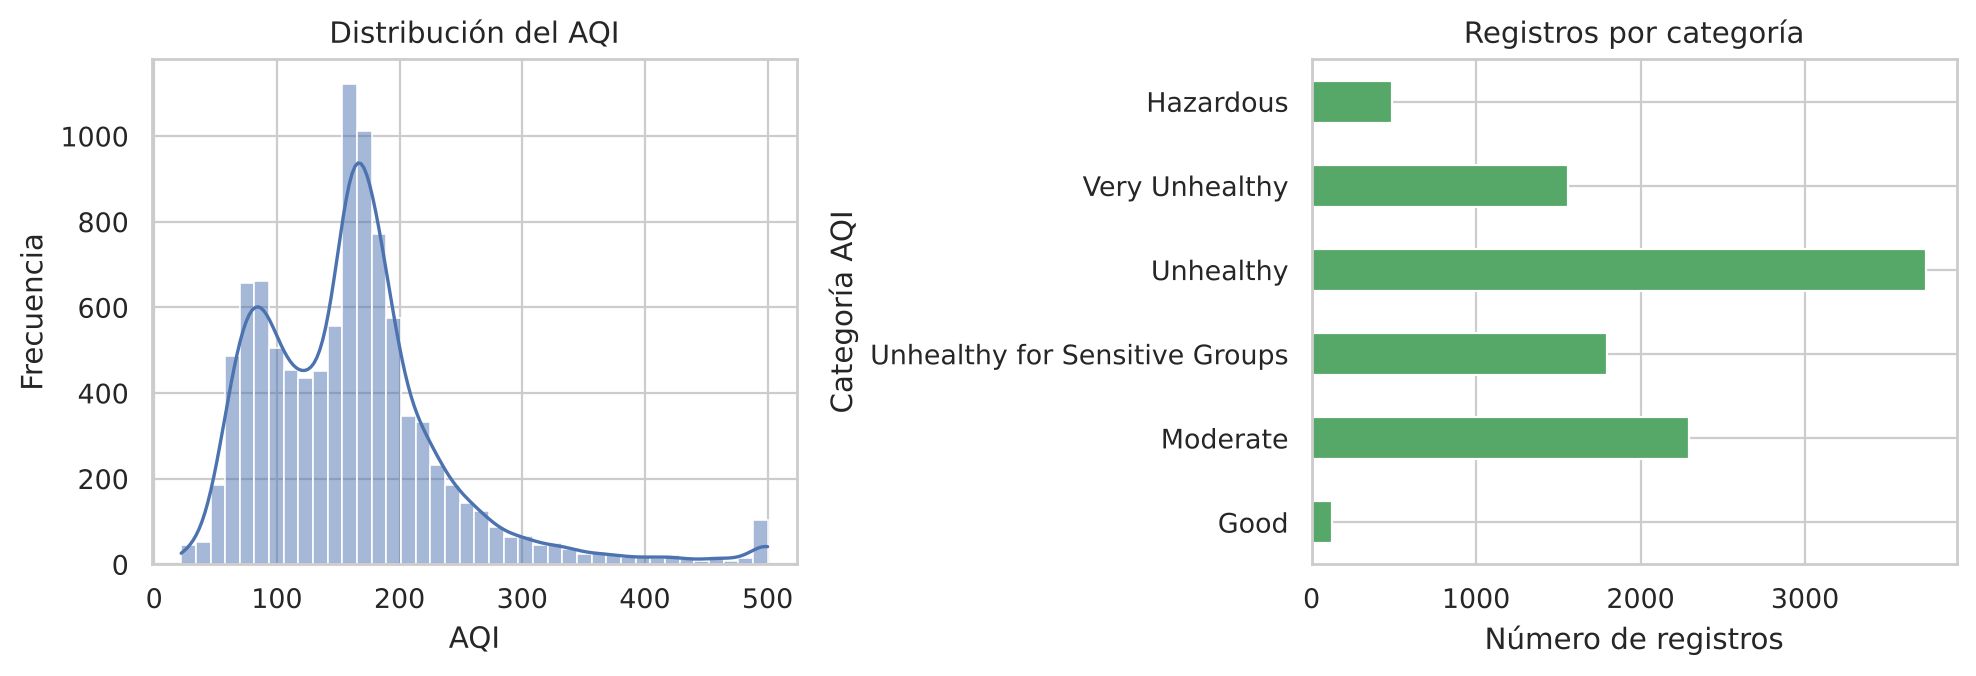

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df["aqi"], bins=40, kde=True, ax=ax[0], color="#4C72B0")
ax[0].set_xlabel("AQI"); ax[0].set_ylabel("Frecuencia"); ax[0].set_title("Distribución del AQI")
orden = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
df["aqi_category"].value_counts().reindex(orden).plot.barh(ax=ax[1], color="#55A868")
ax[1].set_xlabel("Número de registros"); ax[1].set_ylabel("Categoría AQI"); ax[1].set_title("Registros por categoría")
plt.tight_layout()
plt.show()

## 2. Configuración experimental
* Se excluyen `aqi` (variable objetivo) y `aqi_category` (fuga de información: es una
  discretización del propio AQI).
* Partición 80 % entrenamiento / 20 % prueba (`random_state=42`) **estratificada por
  `aqi_category`**: aunque es un problema de regresión, las categorías del AQI son intervalos de la
  variable objetivo, de modo que estratificar por ellas garantiza que los rangos poco frecuentes
  (*Good*, *Hazardous*) tengan la misma proporción en entrenamiento, validación y prueba.
  `aqi_category` se usa **sólo** para hacer la partición, nunca como entrada de los modelos.
* Validación cruzada de 5 folds también estratificada por `aqi_category` (`StratifiedKFold`).
* Preprocesamiento dentro de un `Pipeline` (se ajusta sólo con los folds de entrenamiento):
  `StandardScaler` para las 6 numéricas y `OneHotEncoder(drop='first')` para las 5 categóricas
  → **31 características**.
* Ajuste de hiperparámetros con `GridSearchCV` y los 5 folds estratificados; criterio de
  selección: RMSE de validación. Se registran RMSE, MAE, MedAE y R² de entrenamiento y validación.
* Intervalo de confianza del 95 % sobre los 5 folds: $\bar{x} \pm t_{0.975,4}\, s/\sqrt{5}$.

In [6]:
TARGET = "aqi"
X = df.drop(columns=["aqi", "aqi_category"])
y = df[TARGET]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

estratos = df["aqi_category"]
X_train, X_test, y_train, y_test, estr_train, estr_test = train_test_split(
    X, y, estratos, test_size=0.20, random_state=SEED, stratify=estratos)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(pd.DataFrame({"Total (%)": estratos.value_counts(normalize=True) * 100,
                    "Train (%)": estr_train.value_counts(normalize=True) * 100,
                    "Test (%)": estr_test.value_counts(normalize=True) * 100}).round(2))

def make_preprocessor(cols_num=None, cols_cat=None):
    cols_num = num_cols if cols_num is None else cols_num
    cols_cat = cat_cols if cols_cat is None else cols_cat
    return ColumnTransformer([
        ("num", StandardScaler(), cols_num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cols_cat),
    ])

N_FEATURES = make_preprocessor().fit(X_train).transform(X_train[:5]).shape[1]
print("Número de características tras la codificación:", N_FEATURES)

from sklearn.model_selection import StratifiedKFold
K_FOLDS = 5
# Los folds se generan estratificando por aqi_category y se pasan como lista de índices a
# GridSearchCV / cross_validate (la estratificación no depende del valor continuo del AQI).
CV = list(StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED).split(X_train, estr_train))
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "medae": "neg_median_absolute_error",
    "r2": "r2",
}
T_CRIT = stats.t.ppf(0.975, df=K_FOLDS - 1)

Train: (8000, 11) | Test: (2000, 11)
                                Total (%)  Train (%)  Test (%)
aqi_category                                                  
Unhealthy                           37.35      37.35     37.35
Moderate                            22.93      22.94     22.90
Unhealthy for Sensitive Groups      17.99      17.99     18.00
Very Unhealthy                      15.59      15.59     15.60
Hazardous                            4.89       4.89      4.90
Good                                 1.25       1.25      1.25
Número de características tras la codificación: 31


### Funciones auxiliares
`run_grid` ejecuta la búsqueda en malla y devuelve, para la mejor configuración, las métricas de
entrenamiento y validación (media e IC 95 % sobre los folds) junto con las métricas en test.

In [7]:
def test_metrics(y_true, y_pred):
    return {"rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
            "mae": mean_absolute_error(y_true, y_pred),
            "medae": median_absolute_error(y_true, y_pred),
            "r2": r2_score(y_true, y_pred)}

def summarize(grid, name, Xte=X_test, yte=y_test):
    cvr, i = grid.cv_results_, grid.best_index_
    k = K_FOLDS
    out = {"modelo": name, "best_params": {p.split("__")[-1]: v for p, v in grid.best_params_.items()}}
    for m in SCORING:
        sign = 1 if m == "r2" else -1
        for split in ("train", "test"):
            folds = np.array([cvr[f"split{j}_{split}_{m}"][i] for j in range(k)]) * sign
            tag = "train" if split == "train" else "val"
            out[f"{tag}_{m}"] = folds.mean()
            out[f"{tag}_{m}_ci"] = T_CRIT * folds.std(ddof=1) / np.sqrt(k)
    y_pred = grid.best_estimator_.predict(Xte)
    for m, v in test_metrics(yte, y_pred).items():
        out[f"test_{m}"] = v
    out["fit_time_s"] = cvr["mean_fit_time"][i]
    return out, y_pred

def run_grid(name, pipe, grid_params, Xtr=X_train, ytr=y_train, n_jobs=-1):
    t0 = time.time()
    gs = GridSearchCV(pipe, grid_params, cv=CV, scoring=SCORING, refit="rmse",
                      return_train_score=True, n_jobs=n_jobs)
    gs.fit(Xtr, ytr)
    res, y_pred = summarize(gs, name)
    print(f"{name}: {len(gs.cv_results_['params'])} configuraciones en {time.time()-t0:.0f} s")
    print("  Mejores hiperparámetros:", res["best_params"])
    print(f"  RMSE train {res['train_rmse']:.2f} | val {res['val_rmse']:.2f} ± {res['val_rmse_ci']:.2f}"
          f" | test {res['test_rmse']:.2f} | R² test {res['test_r2']:.3f}")
    return gs, res, y_pred

RESULTS, GRIDS, PREDS = {}, {}, {}

## 3. Entrenamiento y evaluación de los modelos
### 3.1 Modelo paramétrico: regresión lineal regularizada (Ridge) con expansión polinomial
Grado 1 corresponde a la regresión lineal clásica; grado 2 agrega interacciones entre variables.
`alpha` controla la penalización $L_2$ (regularización vista en clase).

In [8]:
pipe_ridge = Pipeline([("prep", make_preprocessor()),
                       ("poly", PolynomialFeatures(include_bias=False)),
                       ("model", Ridge())])
grid_ridge = {"poly__degree": [1, 2],
              "model__alpha": [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]}
GRIDS["Ridge"], RESULTS["Ridge"], PREDS["Ridge"] = run_grid("Ridge", pipe_ridge, grid_ridge)

Ridge: 14 configuraciones en 4 s
  Mejores hiperparámetros: {'alpha': 100, 'degree': 2}
  RMSE train 25.34 | val 26.22 ± 0.58 | test 26.13 | R² test 0.892


### 3.2 Modelo no paramétrico: k vecinos más cercanos (k-NN)

In [9]:
pipe_knn = Pipeline([("prep", make_preprocessor()), ("model", KNeighborsRegressor())])
grid_knn = {"model__n_neighbors": [3, 5, 10, 15, 20, 30, 50],
            "model__weights": ["uniform", "distance"],
            "model__metric": ["euclidean", "manhattan"]}
GRIDS["k-NN"], RESULTS["k-NN"], PREDS["k-NN"] = run_grid("k-NN", pipe_knn, grid_knn)

k-NN: 28 configuraciones en 33 s
  Mejores hiperparámetros: {'metric': 'euclidean', 'n_neighbors': 30, 'weights': 'distance'}
  RMSE train 0.00 | val 28.86 ± 1.24 | test 28.88 | R² test 0.868


### 3.3 Ensamble de árboles: Random Forest

In [10]:
pipe_rf = Pipeline([("prep", make_preprocessor()),
                    ("model", RandomForestRegressor(random_state=SEED, n_jobs=1))])
grid_rf = {"model__n_estimators": [100, 300, 500],
           "model__max_depth": [5, 10, 20, None],
           "model__min_samples_leaf": [1, 5, 10],
           "model__max_features": [0.33, 1.0]}
GRIDS["Random Forest"], RESULTS["Random Forest"], PREDS["Random Forest"] = run_grid(
    "Random Forest", pipe_rf, grid_rf)

Random Forest: 72 configuraciones en 538 s
  Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 500}
  RMSE train 9.54 | val 25.72 ± 0.86 | test 25.72 | R² test 0.896


### 3.4 Red neuronal artificial: perceptrón multicapa (MLP)
Se estandariza también la variable objetivo (`TransformedTargetRegressor`) y se usa parada
temprana para garantizar la convergencia del optimizador.

In [11]:
mlp = TransformedTargetRegressor(
    regressor=MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=20,
                           random_state=SEED),
    transformer=StandardScaler())
pipe_mlp = Pipeline([("prep", make_preprocessor()), ("model", mlp)])
grid_mlp = {"model__regressor__hidden_layer_sizes": [(16,), (64,), (64, 32)],
            "model__regressor__activation": ["relu", "tanh"],
            "model__regressor__alpha": [1e-4, 1e-2, 1, 10]}
GRIDS["MLP"], RESULTS["MLP"], PREDS["MLP"] = run_grid("MLP", pipe_mlp, grid_mlp)

MLP: 24 configuraciones en 52 s
  Mejores hiperparámetros: {'activation': 'relu', 'alpha': 1, 'hidden_layer_sizes': (64, 32)}
  RMSE train 24.66 | val 25.33 ± 0.76 | test 25.03 | R² test 0.901


### 3.5 Máquina de vectores de soporte para regresión (SVR, kernel RBF)
`epsilon` está en unidades de AQI (ancho del tubo de insensibilidad).

In [12]:
pipe_svr = Pipeline([("prep", make_preprocessor()), ("model", SVR(kernel="rbf"))])
# Malla en dos bloques para controlar el costo: los C muy grandes sólo se combinan con kernels
# anchos (gamma pequeño), que es donde tiene sentido aumentar C.
grid_svr = [
    {"model__C": [10, 100, 1000], "model__gamma": ["scale", 0.1, 0.01, 0.001],
     "model__epsilon": [5, 10, 20, 30]},
    {"model__C": [3000, 10000], "model__gamma": [0.01, 0.001], "model__epsilon": [5, 10, 20, 30]},
]
GRIDS["SVR"], RESULTS["SVR"], PREDS["SVR"] = run_grid("SVR", pipe_svr, grid_svr)

SVR: 64 configuraciones en 598 s
  Mejores hiperparámetros: {'C': 3000, 'epsilon': 20, 'gamma': 0.01}
  RMSE train 24.19 | val 25.61 ± 0.75 | test 25.50 | R² test 0.897


### 3.6 Tabla resumen de resultados

In [13]:
def tabla_resultados(results):
    rows = []
    for name, r in results.items():
        rows.append({
            "Modelo": name,
            "RMSE train": r["train_rmse"],
            "RMSE val": f"{r['val_rmse']:.2f} ± {r['val_rmse_ci']:.2f}",
            "MAE val": f"{r['val_mae']:.2f} ± {r['val_mae_ci']:.2f}",
            "R² val": f"{r['val_r2']:.3f} ± {r['val_r2_ci']:.3f}",
            "RMSE test": r["test_rmse"], "MAE test": r["test_mae"],
            "MedAE test": r["test_medae"], "R² test": r["test_r2"],
        })
    return pd.DataFrame(rows).set_index("Modelo")

tabla = tabla_resultados(RESULTS)
pd.set_option("display.precision", 3)
tabla

,RMSE train,RMSE val,MAE val,R² val,RMSE test,MAE test,MedAE test,R² test
Modelo,,,,,,,,
Ridge,2.534e+01,26.22 ± 0.58,19.57 ± 0.48,0.886 ± 0.005,26.131,19.389,16.005,0.892
k-NN,8.578e-06,28.86 ± 1.24,20.76 ± 0.60,0.862 ± 0.010,28.882,20.901,15.936,0.868
Random Forest,9.537e+00,25.72 ± 0.86,18.51 ± 0.52,0.890 ± 0.007,25.718,18.476,14.164,0.896
MLP,2.466e+01,25.33 ± 0.76,18.47 ± 0.60,0.894 ± 0.006,25.031,18.154,13.617,0.901
SVR,2.419e+01,25.61 ± 0.75,18.92 ± 0.49,0.891 ± 0.006,25.502,18.692,14.701,0.897


In [14]:
# Selección de los 2 mejores modelos por RMSE de VALIDACIÓN (no por test)
ranking = sorted(RESULTS, key=lambda n: RESULTS[n]["val_rmse"])
TOP2 = ranking[:2]
print("Ranking por RMSE de validación:", ranking)
print("Mejores 2 modelos:", TOP2)

Ranking por RMSE de validación: ['MLP', 'SVR', 'Random Forest', 'Ridge', 'k-NN']
Mejores 2 modelos: ['MLP', 'SVR']


### 3.7 Efecto de los hiperparámetros
Para cada modelo se varía un hiperparámetro manteniendo los demás en su valor óptimo.
Las barras de error corresponden al IC 95 % sobre los 5 folds.

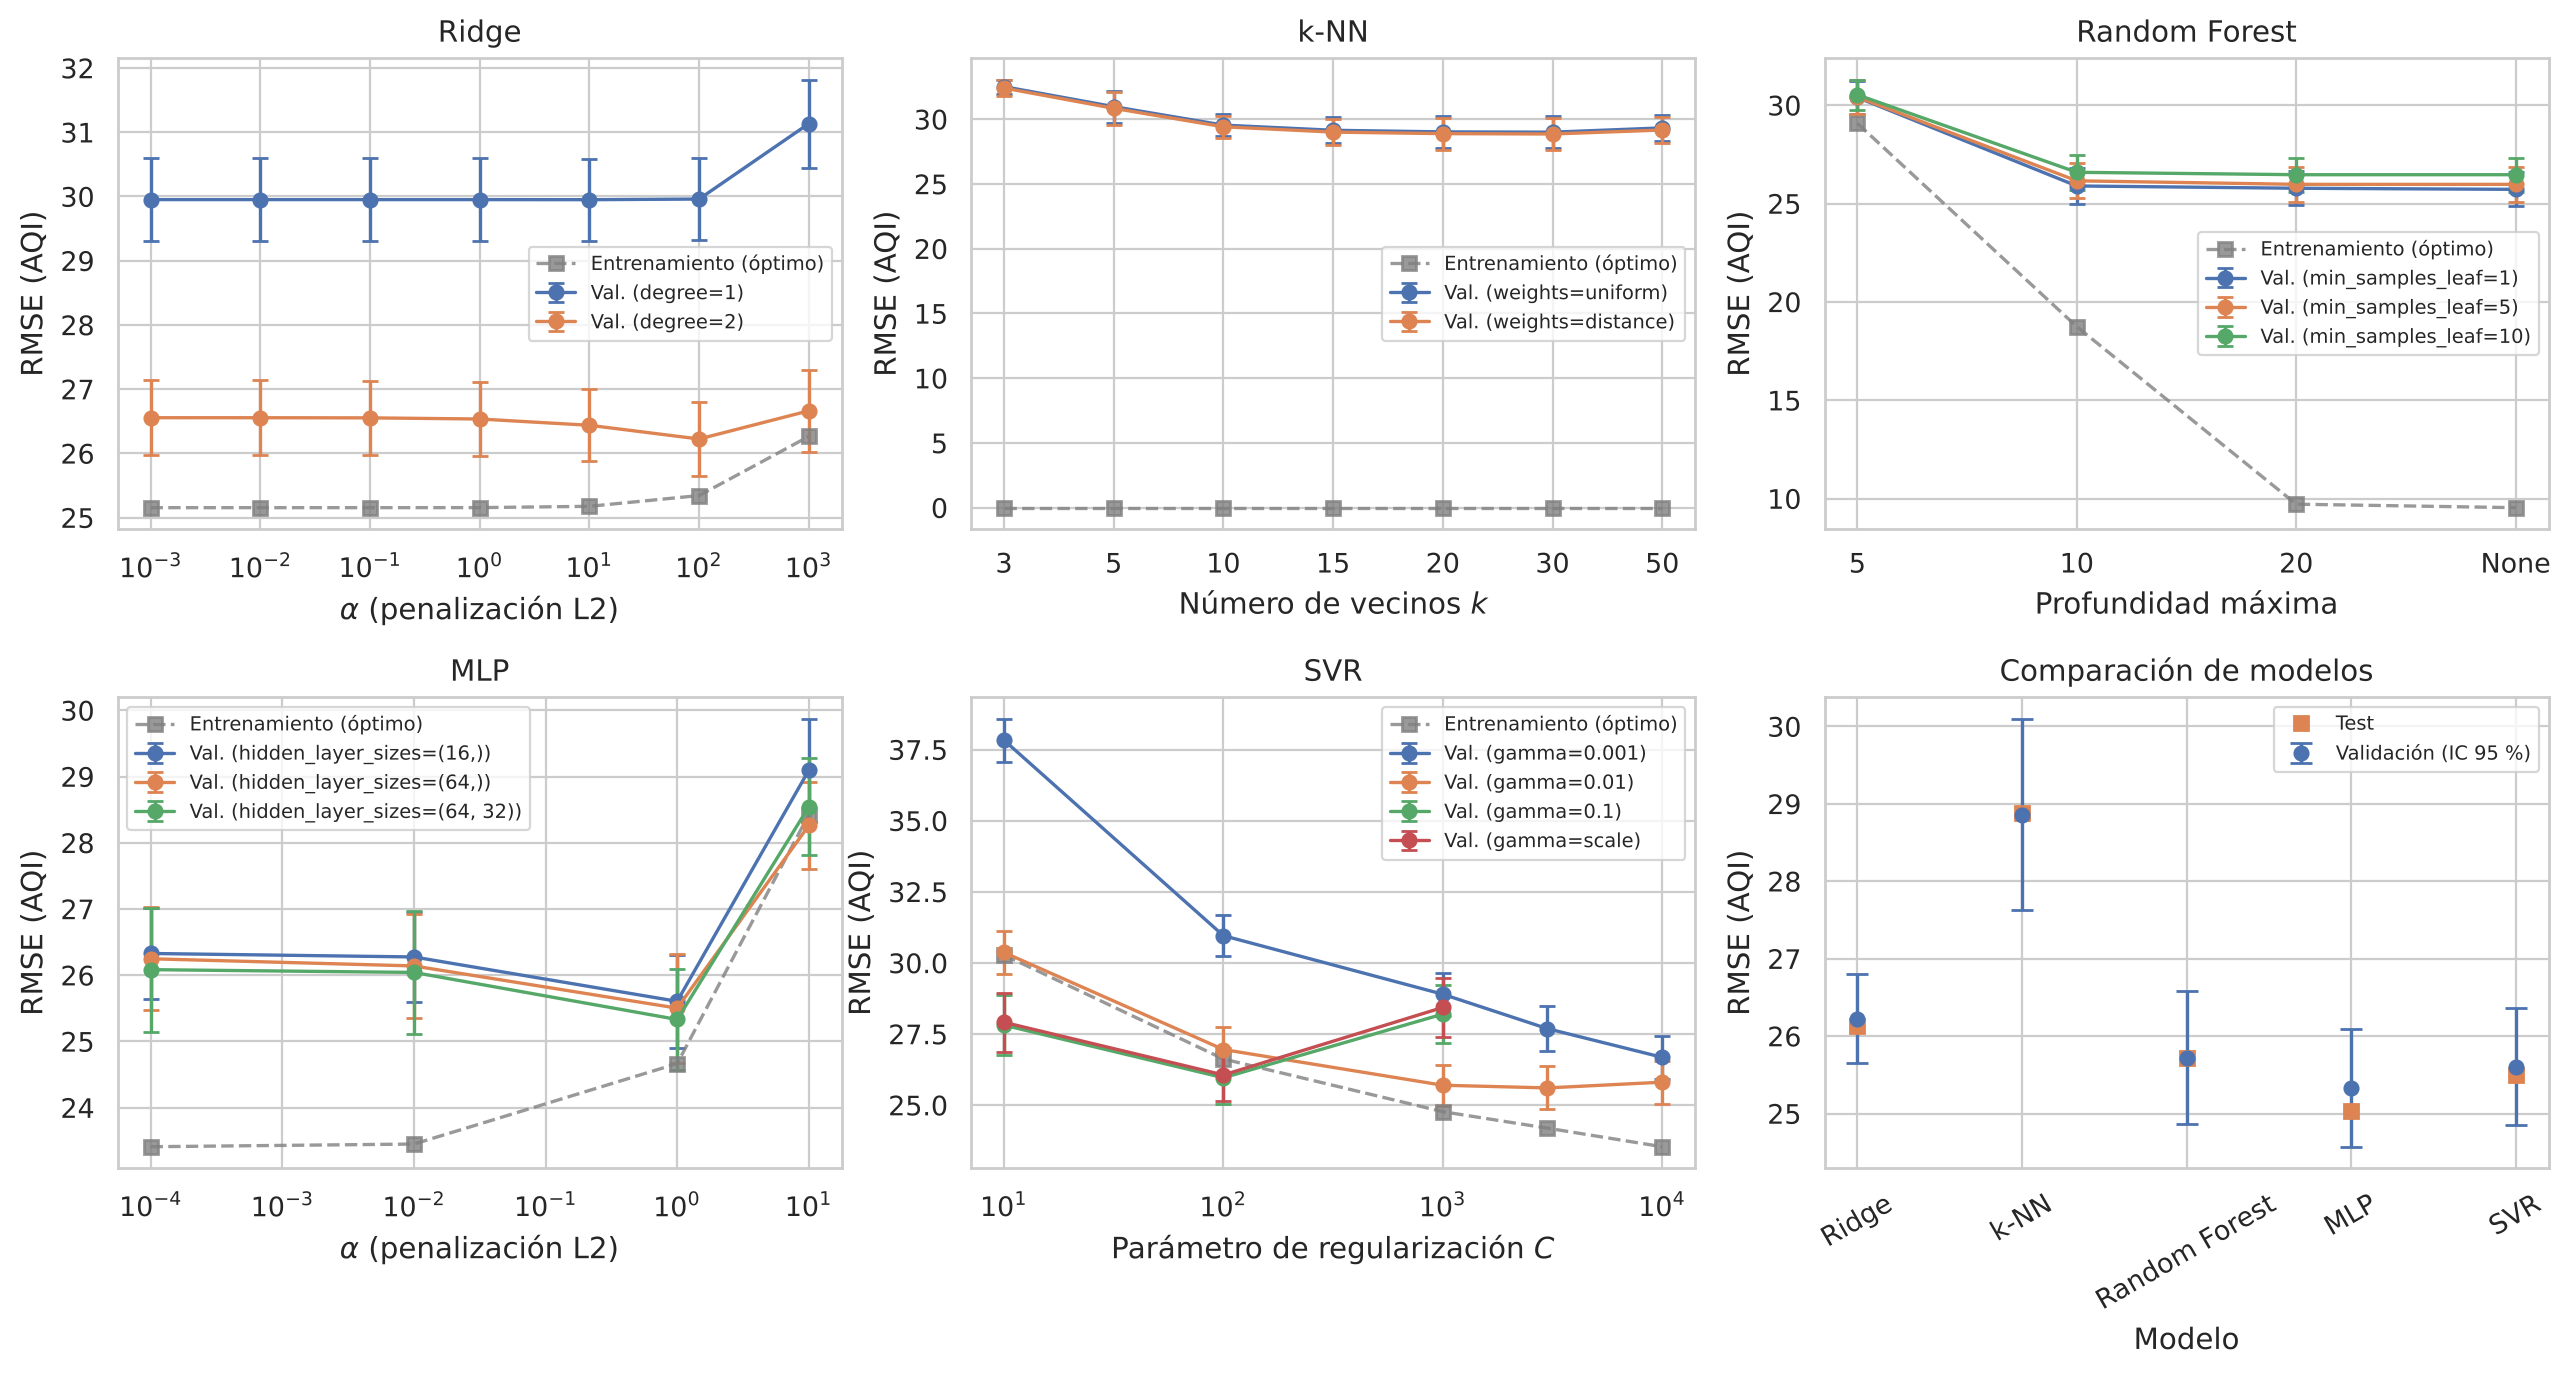

In [15]:
def curva_hiper(ax, name, param, label, logx=False, series=None):
    """RMSE de entrenamiento y validación vs `param`, con los demás hiperparámetros en su óptimo.
    `series` dibuja una curva de validación por cada valor de otro hiperparámetro."""
    gs = GRIDS[name]
    cvr = pd.DataFrame(gs.cv_results_)
    best = gs.best_params_
    k = K_FOLDS
    def fila(fixed):
        mask = np.ones(len(cvr), bool)
        for p, v in fixed.items():
            mask &= cvr["param_" + p].apply(lambda x: (x is None and v is None) or (x is not None and x == v)).values
        return cvr[mask].iloc[0] if mask.any() else None
    def unicos(p):
        vals = list(dict.fromkeys(cvr["param_" + p].tolist()))
        num = sorted([v for v in vals if isinstance(v, (int, float)) and v is not None])
        return num + [v for v in vals if not (isinstance(v, (int, float)) and v is not None)]
    series_vals = [None] if series is None else unicos(series)
    for sv in series_vals:
        fixed = {p: v for p, v in best.items() if p != param and p != series}
        if series is not None: fixed[series] = sv
        valores = [v for v in unicos(param) if fila({**fixed, param: v}) is not None]
        if not valores: continue
        xs = valores if logx else [str(v) for v in valores]
        rows = [fila({**fixed, param: v}) for v in valores]
        val = np.array([-r["mean_test_rmse"] for r in rows])
        trn = np.array([-r["mean_train_rmse"] for r in rows])
        ci = np.array([T_CRIT * r["std_test_rmse"] / np.sqrt(k - 1) for r in rows])  # std poblacional -> IC
        lab = "Validación" if sv is None else f"Val. ({series.split('__')[-1]}={sv})"
        ax.errorbar(xs, val, yerr=ci, marker="o", capsize=3, label=lab)
        if series is None or sv == best[series]:
            ax.plot(xs, trn, "--", marker="s", color="gray", alpha=0.8, label="Entrenamiento (óptimo)")
    if logx: ax.set_xscale("log")
    ax.set_xlabel(label); ax.set_ylabel("RMSE (AQI)"); ax.set_title(name)
    ax.legend(fontsize=7)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
curva_hiper(axes[0, 0], "Ridge", "model__alpha", r"$\alpha$ (penalización L2)", logx=True, series="poly__degree")
curva_hiper(axes[0, 1], "k-NN", "model__n_neighbors", "Número de vecinos $k$", series="model__weights")
curva_hiper(axes[0, 2], "Random Forest", "model__max_depth", "Profundidad máxima", series="model__min_samples_leaf")
curva_hiper(axes[1, 0], "MLP", "model__regressor__alpha", r"$\alpha$ (penalización L2)", logx=True,
            series="model__regressor__hidden_layer_sizes")
curva_hiper(axes[1, 1], "SVR", "model__C", "Parámetro de regularización $C$", logx=True, series="model__gamma")
# Panel final: comparación de modelos en validación (IC 95 %) y test
ax = axes[1, 2]
names = list(RESULTS)
ax.errorbar(names, [RESULTS[n]["val_rmse"] for n in names],
            yerr=[RESULTS[n]["val_rmse_ci"] for n in names], fmt="o", capsize=4, label="Validación (IC 95 %)")
ax.plot(names, [RESULTS[n]["test_rmse"] for n in names], "s", label="Test")
ax.set_xlabel("Modelo"); ax.set_ylabel("RMSE (AQI)"); ax.set_title("Comparación de modelos")
ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.8 Predicciones vs. valores reales en test (2 mejores modelos)

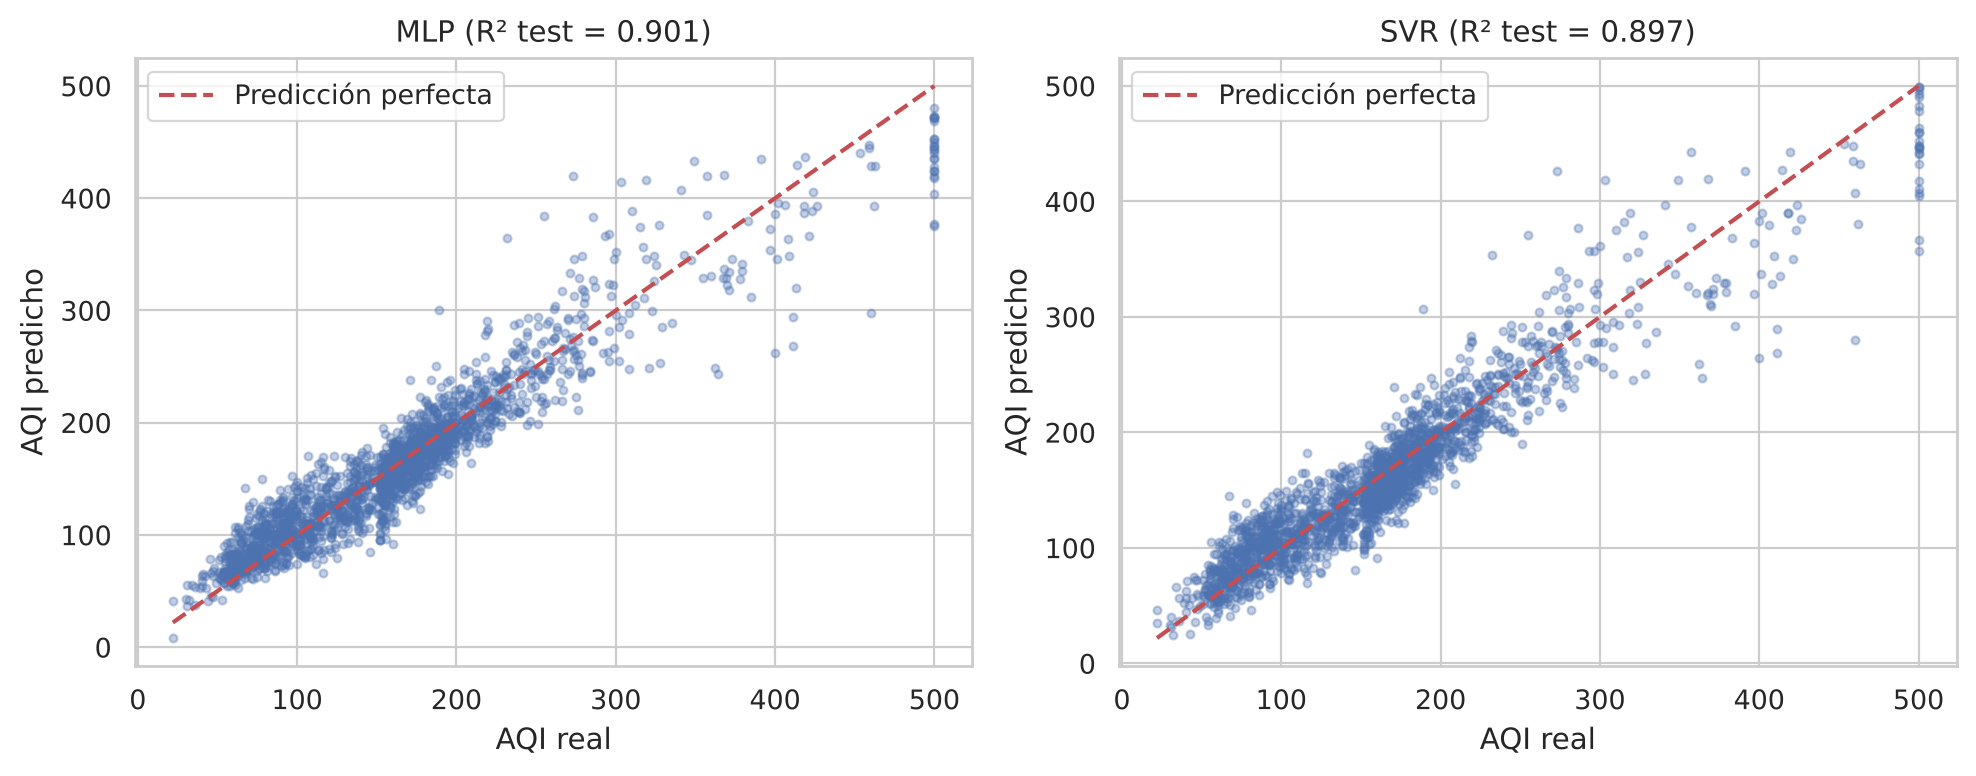

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, TOP2):
    ax.scatter(y_test, PREDS[name], s=8, alpha=0.35)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "r--", lw=1.5, label="Predicción perfecta")
    ax.set_xlabel("AQI real"); ax.set_ylabel("AQI predicho")
    ax.set_title(f"{name} (R² test = {RESULTS[name]['test_r2']:.3f})"); ax.legend()
plt.tight_layout()
plt.show()

## 4. Reducción de dimensión
### 4.1 Análisis individual de variables
Todo el análisis se hace **sólo con el conjunto de entrenamiento**.
* Numéricas: correlación de Pearson y Spearman con el AQI.
* Categóricas: razón de correlación $\eta^2$ (fracción de la varianza del AQI explicada por la
  variable) y prueba F de ANOVA.
* Todas: información mutua (captura dependencias no lineales).
* Redundancia: V de Cramér entre categóricas y correlación entre numéricas.

In [17]:
tr = X_train.copy(); tr["aqi"] = y_train.values

def eta2(cat, yv):
    g = pd.DataFrame({"c": cat, "y": yv}).groupby("c")["y"]
    ss_between = (g.count() * (g.mean() - yv.mean()) ** 2).sum()
    return ss_between / ((yv - yv.mean()) ** 2).sum()

# información mutua con codificación ordinal de las categóricas
Xmi = X_train.copy()
for c in cat_cols:
    Xmi[c] = Xmi[c].astype("category").cat.codes
mi = mutual_info_regression(Xmi, y_train, discrete_features=[c in cat_cols for c in Xmi.columns],
                            random_state=SEED)
mi = pd.Series(mi, index=Xmi.columns)

filas = []
for c in X.columns:
    if c in num_cols:
        filas.append({"Variable": c, "Tipo": "Numérica",
                      "Pearson r": tr[c].corr(tr["aqi"]),
                      "Spearman ρ": tr[c].corr(tr["aqi"], method="spearman"),
                      "η²": np.nan, "IM": mi[c]})
    else:
        F, p = stats.f_oneway(*[g.values for _, g in tr.groupby(c)["aqi"]])
        filas.append({"Variable": c, "Tipo": "Categórica", "Pearson r": np.nan, "Spearman ρ": np.nan,
                      "η²": eta2(tr[c], tr["aqi"]), "IM": mi[c], "F ANOVA": F, "p-valor": p})
analisis = pd.DataFrame(filas).set_index("Variable").sort_values("IM", ascending=False)
analisis

,Tipo,Pearson r,Spearman ρ,η²,IM,F ANOVA,p-valor
Variable,,,,,,,
visibility_km,Numérica,-0.907,-0.897,NaN,0.907,NaN,NaN
pressure_hpa,Numérica,0.624,0.711,NaN,0.336,NaN,NaN
temperature_c,Numérica,-0.551,-0.565,NaN,0.257,NaN,NaN
rainfall_mm,Numérica,-0.350,-0.481,NaN,0.177,NaN,NaN
humidity_pct,Numérica,-0.364,-0.425,NaN,0.125,NaN,NaN
wind_direction,Categórica,NaN,NaN,0.117,0.067,151.770,3.631e-211
area,Categórica,NaN,NaN,0.095,0.059,76.225,5.693e-164
wind_speed_kmh,Numérica,-0.267,-0.283,NaN,0.058,NaN,NaN
station_type,Categórica,NaN,NaN,0.088,0.053,257.875,9.421e-160


Tabla de contingencia area × station_type (entrenamiento):


station_type,background,industrial,residential,roadside
area,,,,
Agargaon,0,0,0,628
Baridhara,709,0,0,0
Dhanmondi,0,0,0,634
Gulshan,0,0,666,0
Hazaribagh,0,677,0,0
Jatrabari,0,648,0,0
Mirpur,0,0,690,0
Mohammadpur,0,0,697,0
Motijheel,0,0,0,643


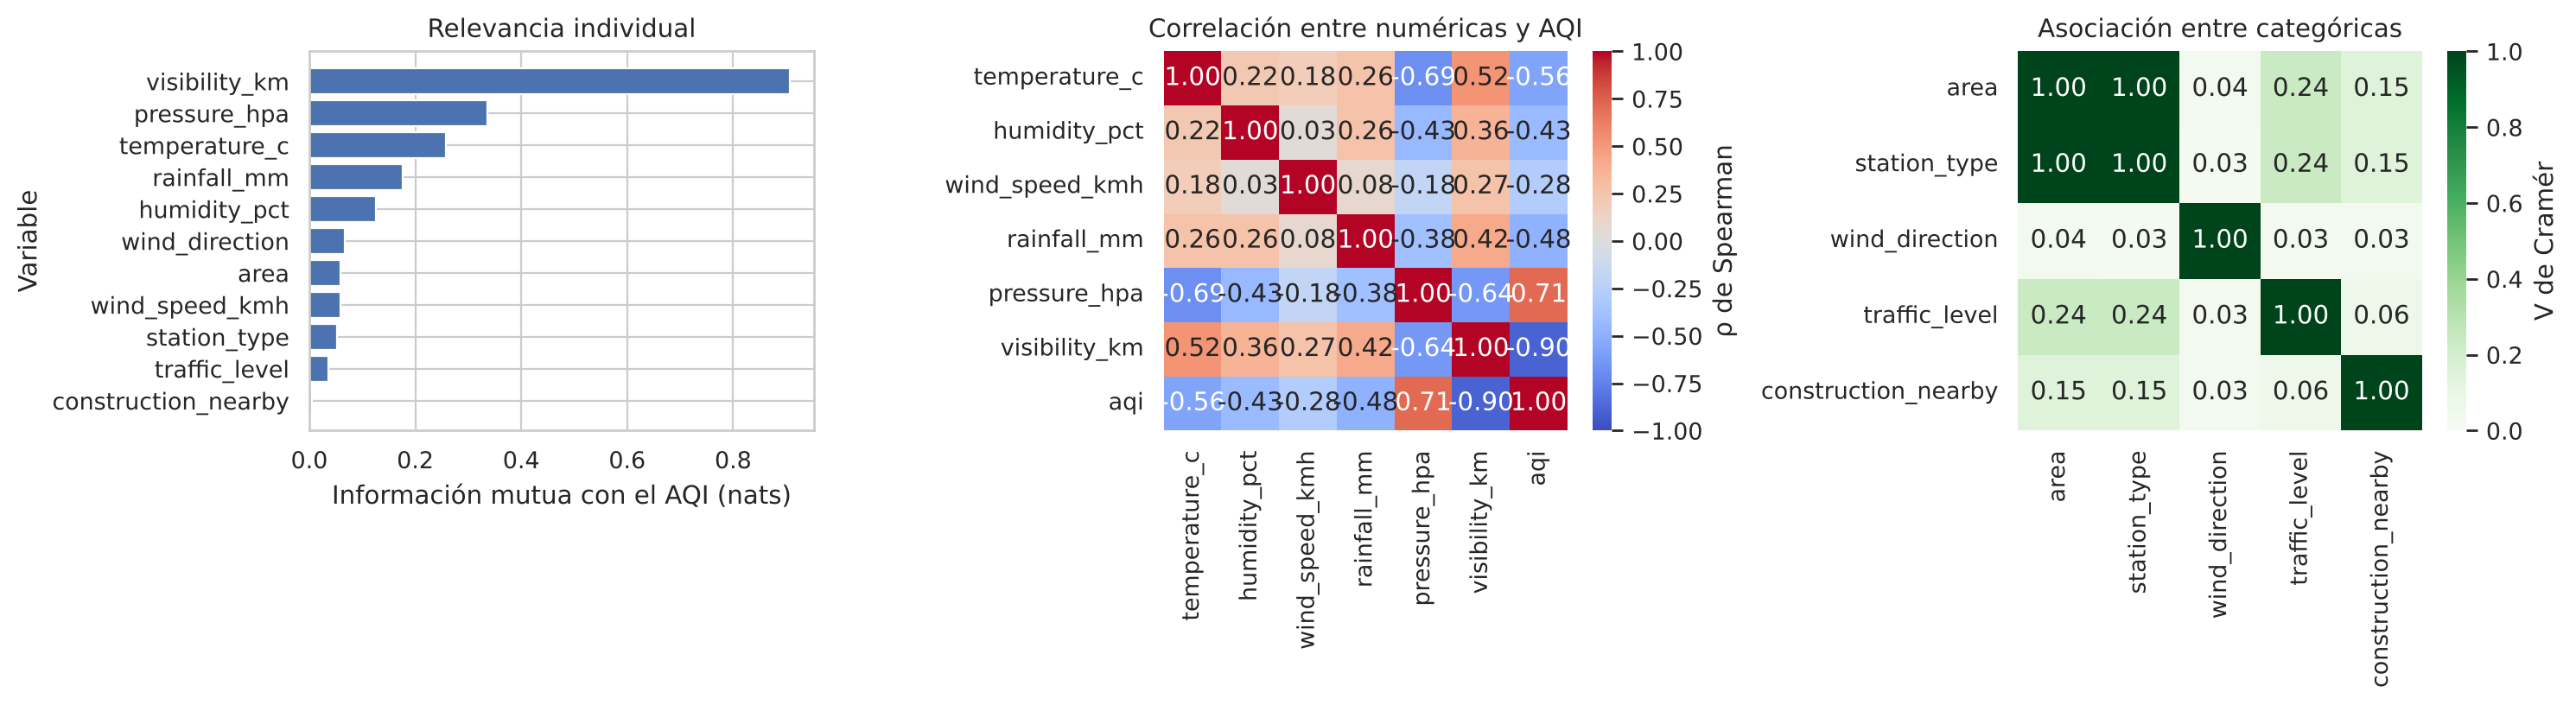

In [18]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cv_mat = pd.DataFrame([[cramers_v(tr[a], tr[b]) for b in cat_cols] for a in cat_cols],
                      index=cat_cols, columns=cat_cols)
print("Tabla de contingencia area × station_type (entrenamiento):")
display(pd.crosstab(tr["area"], tr["station_type"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
imp = analisis["IM"].sort_values()
axes[0].barh(imp.index, imp.values, color="#4C72B0")
axes[0].set_xlabel("Información mutua con el AQI (nats)"); axes[0].set_ylabel("Variable")
axes[0].set_title("Relevancia individual")
sns.heatmap(tr[num_cols + ["aqi"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[1], cbar_kws={"label": "ρ de Spearman"})
axes[1].set_title("Correlación entre numéricas y AQI")
sns.heatmap(cv_mat, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=axes[2],
            cbar_kws={"label": "V de Cramér"})
axes[2].set_title("Asociación entre categóricas")
plt.tight_layout()
plt.show()

**Selección por consenso.** Los métodos de selección no siempre coinciden, por lo que se aplica un
mecanismo de consenso: en **cada uno de los 5 folds** (usando sólo sus datos de entrenamiento) se
calcula la relevancia de las 11 variables con 4 métodos de naturaleza distinta:

1. **Filtro lineal:** fracción de la varianza del AQI explicada por la variable ($r^2$ de Pearson
   para numéricas, $\eta^2$ para categóricas; ambas son comparables).
2. **Filtro no lineal:** información mutua.
3. **Integrado (embedded) — Lasso ($L_1$):** suma de los $|\beta|$ de las columnas de cada variable
   (todas estandarizadas), con $\lambda$ elegido por validación cruzada interna.
4. **Integrado — Random Forest:** suma de las importancias de las columnas de cada variable.

Cada método decide si la variable es relevante con un criterio objetivo:
* Filtro lineal: prueba F (Pearson / ANOVA) significativa con corrección de Bonferroni ($p < 0{,}05/p$).
* Información mutua y Random Forest: la variable debe superar la importancia de **variables sonda**
  (3 columnas de ruido aleatorio añadidas a los datos); si no supera al ruido, no aporta.
* Lasso: al menos uno de sus coeficientes es distinto de cero.

La variable se conserva en el conjunto final si es seleccionada en al menos el 50 % de las 20
evaluaciones (4 métodos × 5 folds). Además, se elimina
la redundancia detectada con la V de Cramér.

In [19]:
from sklearn.linear_model import LassoCV

def importancia_por_variable(cols_trans, valores, normalizar=True):
    """Agrega importancias de columnas codificadas a la variable original."""
    out = pd.Series(0.0, index=X.columns)
    for c, v in zip(cols_trans, valores):
        nombre = c.split("__", 1)[1]
        var = nombre if nombre in num_cols else next(v_ for v_ in cat_cols if nombre.startswith(v_ + "_"))
        out[var] += abs(v)
    return out / out.sum() if normalizar else out

P = len(X.columns)
N_SONDAS = 3
rng = np.random.default_rng(SEED)
registros = []
for f, (tr_idx, _) in enumerate(CV):
    Xf, yf = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    sondas = rng.normal(size=(len(Xf), N_SONDAS))
    # 1. filtro lineal: prueba F (Pearson para numéricas, ANOVA para categóricas) con Bonferroni
    pvals = {}
    for c in X.columns:
        if c in num_cols:
            pvals[c] = stats.pearsonr(Xf[c], yf)[1]
        else:
            pvals[c] = stats.f_oneway(*[g.values for _, g in yf.groupby(Xf[c].values)])[1]
    sel_lin = pd.Series({c: pvals[c] < 0.05 / P for c in X.columns})
    # 2. información mutua vs. sondas de ruido
    Xm = Xf.copy()
    for c in cat_cols: Xm[c] = Xm[c].astype("category").cat.codes
    Xm = np.column_stack([Xm.values, sondas])
    disc = [c in cat_cols for c in X.columns] + [False] * N_SONDAS
    mi_f = mutual_info_regression(Xm, yf, discrete_features=disc, random_state=SEED)
    sel_mi = pd.Series(mi_f[:P] > mi_f[P:].max(), index=X.columns)
    # 3. Lasso (columnas estandarizadas, lambda por validación cruzada interna)
    prep_f = make_preprocessor().fit(Xf)
    Tf = prep_f.transform(Xf)
    nombres = prep_f.get_feature_names_out()
    lasso = LassoCV(cv=5, random_state=SEED, n_jobs=-1).fit(StandardScaler().fit_transform(Tf), yf)
    sel_las = importancia_por_variable(nombres, lasso.coef_, normalizar=False) > 0
    # 4. Random Forest vs. sondas de ruido
    rf_f = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
    rf_f.fit(np.column_stack([Tf, sondas]), yf)
    imp_rf = rf_f.feature_importances_
    sel_rf = importancia_por_variable(nombres, imp_rf[:Tf.shape[1]], normalizar=False) > imp_rf[Tf.shape[1]:].max()
    for metodo, sel in [("Filtro F (Bonferroni)", sel_lin), ("Info. mutua vs. ruido", sel_mi),
                        ("Lasso (L1)", sel_las), ("Random Forest vs. ruido", sel_rf)]:
        for var in X.columns:
            registros.append({"fold": f, "metodo": metodo, "variable": var, "seleccionada": bool(sel[var])})
consenso_df = pd.DataFrame(registros)
frecuencia = consenso_df.groupby("variable")["seleccionada"].mean().sort_values(ascending=False)
por_metodo = consenso_df.pivot_table(index="variable", columns="metodo", values="seleccionada",
                                     aggfunc="mean").loc[frecuencia.index]
por_metodo["Consenso (%)"] = frecuencia * 100
VARS_CONSENSO = frecuencia[frecuencia >= 0.5].index.tolist()
# redundancia: station_type está determinada por area (V de Cramér = 1)
if "station_type" in VARS_CONSENSO and "area" in VARS_CONSENSO:
    VARS_CONSENSO_SIN_RED = [v for v in VARS_CONSENSO if v != "station_type"]
else:
    VARS_CONSENSO_SIN_RED = VARS_CONSENSO
DESCARTADAS = [v for v in X.columns if v not in VARS_CONSENSO]
print("Variables descartadas por consenso:", DESCARTADAS)
(por_metodo * 100).round(0)

Variables descartadas por consenso: []


metodo,Filtro F (Bonferroni),Info. mutua vs. ruido,Lasso (L1),Random Forest vs. ruido,Consenso (%)
variable,,,,,
humidity_pct,100.0,100.0,100.0,100.0,10000.0
rainfall_mm,100.0,100.0,100.0,100.0,10000.0
pressure_hpa,100.0,100.0,100.0,100.0,10000.0
wind_speed_kmh,100.0,100.0,100.0,100.0,10000.0
visibility_km,100.0,100.0,100.0,100.0,10000.0
temperature_c,100.0,100.0,100.0,100.0,10000.0
area,100.0,100.0,100.0,0.0,7500.0
traffic_level,100.0,100.0,100.0,0.0,7500.0
station_type,100.0,100.0,100.0,0.0,7500.0


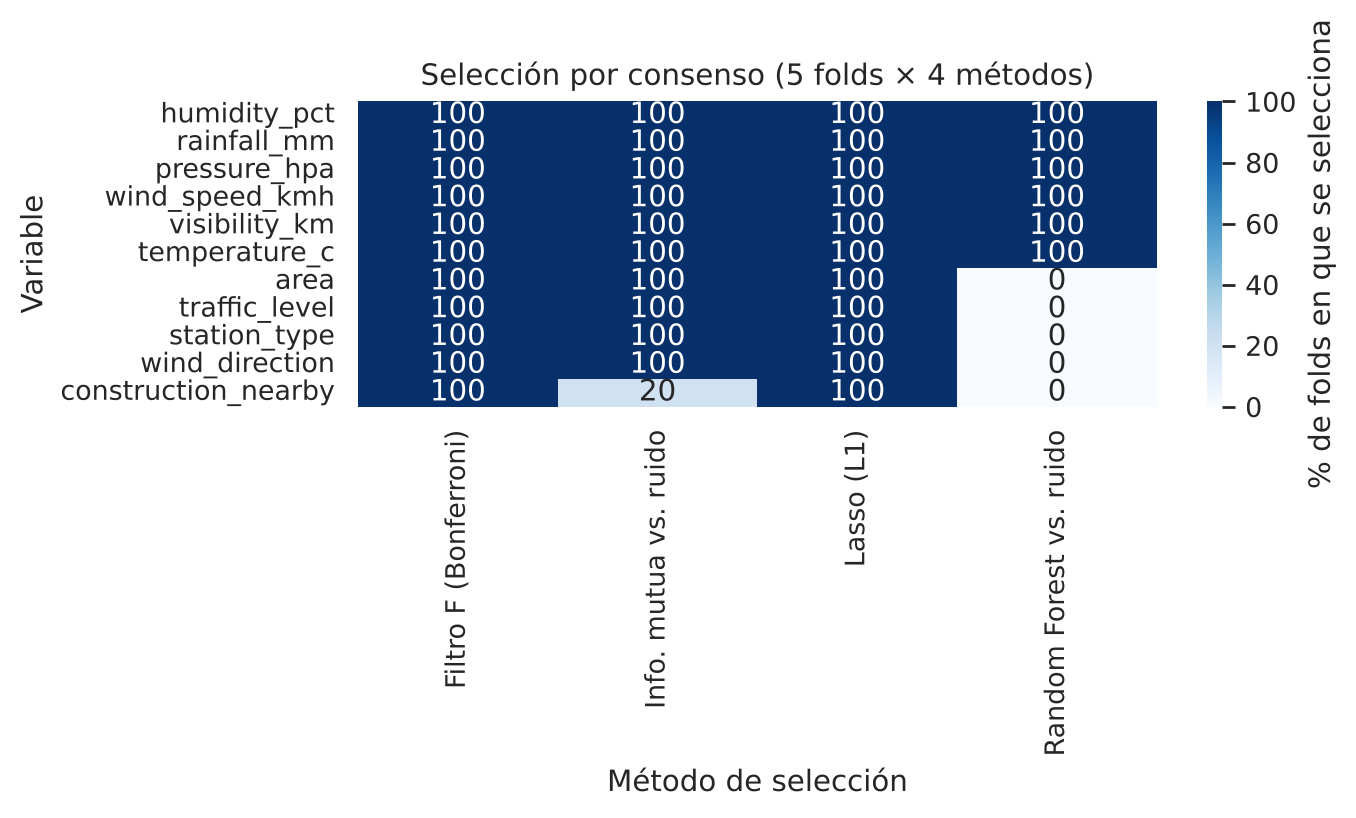

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(por_metodo.drop(columns="Consenso (%)") * 100, annot=True, fmt=".0f", cmap="Blues",
            vmin=0, vmax=100, cbar_kws={"label": "% de folds en que se selecciona"}, ax=ax)
ax.set_xlabel("Método de selección"); ax.set_ylabel("Variable")
ax.set_title("Selección por consenso (5 folds × 4 métodos)")
plt.tight_layout()
plt.show()

Se evalúan los 2 mejores modelos (hiperparámetros óptimos) con validación cruzada usando: todas
las variables, el subconjunto de consenso y el subconjunto de consenso sin la variable redundante.

In [21]:
escenarios = {"Todas las variables": list(X.columns),
              "Consenso": VARS_CONSENSO,
              "Consenso sin redundancia": VARS_CONSENSO_SIN_RED}
filas_sel = []
for name in TOP2:
    best_pipe = GRIDS[name].best_estimator_
    for esc, cols in escenarios.items():
        pipe = clone(best_pipe)
        pipe.set_params(prep=make_preprocessor([c for c in num_cols if c in cols],
                                               [c for c in cat_cols if c in cols]))
        cvres = cross_validate(pipe, X_train[cols], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        pipe.fit(X_train[cols], y_train)
        tm = test_metrics(y_test, pipe.predict(X_test[cols]))
        n_feat = pipe.named_steps["prep"].transform(X_train[cols][:2]).shape[1]
        rm = -cvres["test_rmse"]
        filas_sel.append({"Modelo": name, "Escenario": esc, "Variables": len(cols), "Dimensión": n_feat,
                          "RMSE val": f"{rm.mean():.2f} ± {T_CRIT*rm.std(ddof=1)/np.sqrt(K_FOLDS):.2f}",
                          "RMSE test": tm["rmse"], "R² test": tm["r2"]})
seleccion = pd.DataFrame(filas_sel)
seleccion

,Modelo,Escenario,Variables,Dimensión,RMSE val,RMSE test,R² test
0,MLP,Todas las variables,11,31,25.33 ± 0.76,25.031,0.901
1,MLP,Consenso,11,31,25.33 ± 0.76,25.031,0.901
2,MLP,Consenso sin redundancia,10,28,25.26 ± 0.89,25.103,0.900
3,SVR,Todas las variables,11,31,25.61 ± 0.75,25.502,0.897
4,SVR,Consenso,11,31,25.61 ± 0.75,25.502,0.897
5,SVR,Consenso sin redundancia,10,28,25.57 ± 0.76,25.388,0.898


### 4.2 Extracción lineal: PCA
El PCA se aplica sobre las 31 características ya estandarizadas/codificadas, dentro del pipeline.
**Criterio:** número mínimo de componentes que retiene al menos el 90 % (y 95 %) de la varianza,
calculado **en cada fold** y combinado con un mecanismo de consenso (el máximo entre folds, para
garantizar el umbral en todos). Además, se hace una búsqueda tipo *wrapper* sobre el número de
componentes junto con un **nuevo ajuste de hiperparámetros** de los 2 mejores modelos.

Componentes para 90 % por fold: [16, 16, 16, 16, 16] | para 95 %: [21, 21, 21, 21, 21]
Consenso → 90 %: 16 componentes | 95 %: 21 componentes (de 31)


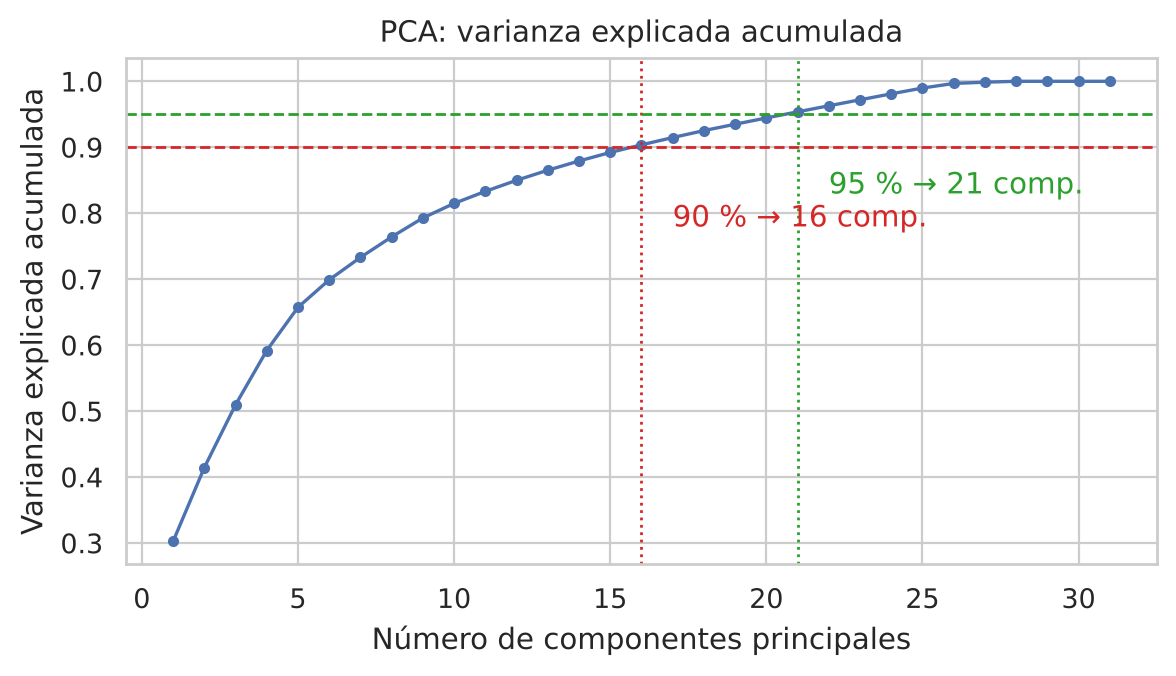

In [22]:
Z = make_preprocessor().fit_transform(X_train)
pca_full = PCA().fit(Z)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
K90 = int(np.argmax(var_acum >= 0.90) + 1)
K95 = int(np.argmax(var_acum >= 0.95) + 1)
k90_folds, k95_folds = [], []
for tr_idx, _ in CV:
    vf = np.cumsum(PCA().fit(make_preprocessor().fit_transform(X_train.iloc[tr_idx])).explained_variance_ratio_)
    k90_folds.append(int(np.argmax(vf >= 0.90) + 1)); k95_folds.append(int(np.argmax(vf >= 0.95) + 1))
print("Componentes para 90 % por fold:", k90_folds, "| para 95 %:", k95_folds)
K90, K95 = max(k90_folds), max(k95_folds)   # consenso: máximo entre folds
print(f"Consenso → 90 %: {K90} componentes | 95 %: {K95} componentes (de {N_FEATURES})")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, N_FEATURES + 1), var_acum, marker="o", ms=3)
for th, kk, col in [(0.90, K90, "tab:red"), (0.95, K95, "tab:green")]:
    ax.axhline(th, ls="--", color=col, lw=1); ax.axvline(kk, ls=":", color=col, lw=1)
    ax.annotate(f"{int(th*100)} % → {kk} comp.", (kk, th), xytext=(kk + 1, th - 0.12), color=col)
ax.set_xlabel("Número de componentes principales"); ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA: varianza explicada acumulada")
plt.tight_layout()
plt.show()

In [23]:
# Mallas reducidas alrededor de los óptimos para el re-ajuste en los espacios transformados
GRID_REDUCIDA = {
    "Ridge": {"poly__degree": [1, 2], "model__alpha": [1e-2, 1, 100]},
    "k-NN": {"model__n_neighbors": [10, 20, 30, 50], "model__weights": ["uniform", "distance"]},
    "Random Forest": {"model__n_estimators": [500], "model__max_depth": [20, None],
                      "model__min_samples_leaf": [1, 5], "model__max_features": [0.33, 1.0]},
    "MLP": {"model__regressor__hidden_layer_sizes": [(16,), (64,), (64, 32)],
            "model__regressor__alpha": [1e-2, 1, 10]},
    "SVR": {"model__C": [10, 100, 1000], "model__gamma": ["scale", 0.1, 0.01], "model__epsilon": [10, 20, 30]},
}

from itertools import product
from joblib import Parallel, delayed

def modelo_base(name):
    """Pasos del mejor pipeline de la sección 3, sin el preprocesamiento."""
    return Pipeline([(n, clone(st)) for n, st in GRIDS[name].best_estimator_.steps if n != "prep"])

def _ajustar_evaluar(base, params, Ztr, ytr, Zva, yva):
    m = clone(base).set_params(**params).fit(Ztr, ytr)
    return test_metrics(ytr, m.predict(Ztr)), test_metrics(yva, m.predict(Zva))

def evaluar_reduccion(metodo, make_reductor, n_comp_grid):
    """Validación cruzada (5 folds) de los 2 mejores modelos en el espacio reducido.
    En cada fold el preprocesamiento y el reductor se ajustan SÓLO con los datos de entrenamiento
    del fold; el reductor se ajusta una vez por fold y número de componentes, y sobre ese espacio se
    re-ajustan los hiperparámetros del modelo (búsqueda en malla)."""
    # 1. Espacios reducidos por fold y número de componentes
    folds = []
    for tr_idx, va_idx in CV:
        Xtr, Xva = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        prep = make_preprocessor().fit(Xtr)
        Ptr, Pva = prep.transform(Xtr), prep.transform(Xva)
        esp = {}
        for k in n_comp_grid:
            red = make_reductor(k).fit(Ptr)
            esp[k] = (red.transform(Ptr), red.transform(Pva))
        folds.append((esp, y_train.iloc[tr_idx], y_train.iloc[va_idx]))
    filas, curvas = [], {}
    for name in TOP2:
        t0 = time.time()
        grid = GRID_REDUCIDA[name]
        combos = [dict(zip(grid, v)) for v in product(*grid.values())]
        tareas = [(k, c, f) for k in n_comp_grid for c in combos for f in range(len(folds))]
        base = modelo_base(name)
        out = Parallel(n_jobs=-1)(delayed(_ajustar_evaluar)(base, c, folds[f][0][k][0], folds[f][1],
                                                              folds[f][0][k][1], folds[f][2])
                                  for k, c, f in tareas)
        reg = pd.DataFrame([{"k": k, "cfg": str(c), "fold": f,
                             **{f"train_{m}": tm[m] for m in tm}, **{f"val_{m}": vm[m] for m in vm}}
                            for (k, c, f), (tm, vm) in zip(tareas, out)])
        agg = reg.groupby(["k", "cfg"]).agg(["mean", "std"])
        best_k, best_cfg = agg[("val_rmse", "mean")].idxmin()
        res = {"modelo": f"{name} + {metodo}", "n_comp": int(best_k),
               "reduccion": 100 * (1 - best_k / N_FEATURES),
               "best_params": {p.split("__")[-1]: v for p, v in eval(best_cfg).items()}}
        nf = len(folds)
        for m in SCORING:
            for tag in ("train", "val"):
                res[f"{tag}_{m}"] = agg.loc[(best_k, best_cfg), (f"{tag}_{m}", "mean")]
                res[f"{tag}_{m}_ci"] = T_CRIT * agg.loc[(best_k, best_cfg), (f"{tag}_{m}", "std")] / np.sqrt(nf)
        # curva: mejor configuración por número de componentes
        mejor_k = agg[("val_rmse", "mean")].groupby(level=0).idxmin()
        curvas[name] = pd.DataFrame({
            "k": [k for k, _ in mejor_k],
            "rmse": [agg.loc[i, ("val_rmse", "mean")] for i in mejor_k],
            "ci": [T_CRIT * agg.loc[i, ("val_rmse", "std")] / np.sqrt(nf) for i in mejor_k]})
        # 2. Re-entrenar con todo el conjunto de entrenamiento y evaluar en test
        final = Pipeline([("prep", make_preprocessor()), ("red", make_reductor(best_k)),
                          *modelo_base(name).set_params(**eval(best_cfg)).steps])
        final.fit(X_train, y_train)
        for m, v in test_metrics(y_test, final.predict(X_test)).items():
            res[f"test_{m}"] = v
        filas.append(res)
        print(f"{name} + {metodo}: k={best_k} ({res['reduccion']:.0f} % de reducción), "
              f"{res['best_params']} | RMSE val {res['val_rmse']:.2f} ± {res['val_rmse_ci']:.2f} "
              f"| test {res['test_rmse']:.2f} | R² test {res['test_r2']:.3f} [{time.time()-t0:.0f} s]")
    return filas, curvas

PCA_RES, PCA_CURVAS = evaluar_reduccion("PCA", lambda k: PCA(n_components=k, random_state=SEED),
                                        sorted({5, 10, K90, K95}))

MLP + PCA: k=21 (32 % de reducción), {'hidden_layer_sizes': (64,), 'alpha': 1} | RMSE val 25.42 ± 0.82 | test 25.34 | R² test 0.899 [55 s]


SVR + PCA: k=10 (68 % de reducción), {'C': 100, 'gamma': 0.1, 'epsilon': 10} | RMSE val 25.43 ± 1.35 | test 24.77 | R² test 0.903 [491 s]


### 4.3 Extracción no lineal: UMAP
UMAP se ajusta de forma **no supervisada** (sin usar el AQI) dentro del pipeline, de modo que en
cada fold sólo ve los datos de entrenamiento. **Criterio:** *wrapper* sobre el número de
componentes (2, 5, 10 y 15) eligiendo el de menor RMSE de validación, con re-ajuste de los
hiperparámetros de cada modelo.

In [24]:
class UMAPNoSupervisado(BaseEstimator, TransformerMixin):
    """Envuelve UMAP para que ignore `y` dentro del Pipeline (UMAP no supervisado)."""
    def __init__(self, n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED):
        self.n_components = n_components; self.n_neighbors = n_neighbors
        self.min_dist = min_dist; self.random_state = random_state
    def fit(self, X, y=None):
        self.umap_ = umap.UMAP(n_components=self.n_components, n_neighbors=self.n_neighbors,
                               min_dist=self.min_dist, random_state=self.random_state).fit(X)
        return self
    def transform(self, X):
        return self.umap_.transform(X)

UMAP_RES, UMAP_CURVAS = evaluar_reduccion("UMAP", lambda k: UMAPNoSupervisado(n_components=k), [2, 5, 10, 15])

MLP + UMAP: k=10 (68 % de reducción), {'hidden_layer_sizes': (64, 32), 'alpha': 0.01} | RMSE val 35.61 ± 1.68 | test 36.15 | R² test 0.794 [133 s]


SVR + UMAP: k=10 (68 % de reducción), {'C': 1000, 'gamma': 0.1, 'epsilon': 20} | RMSE val 33.14 ± 1.70 | test 33.35 | R² test 0.824 [326 s]


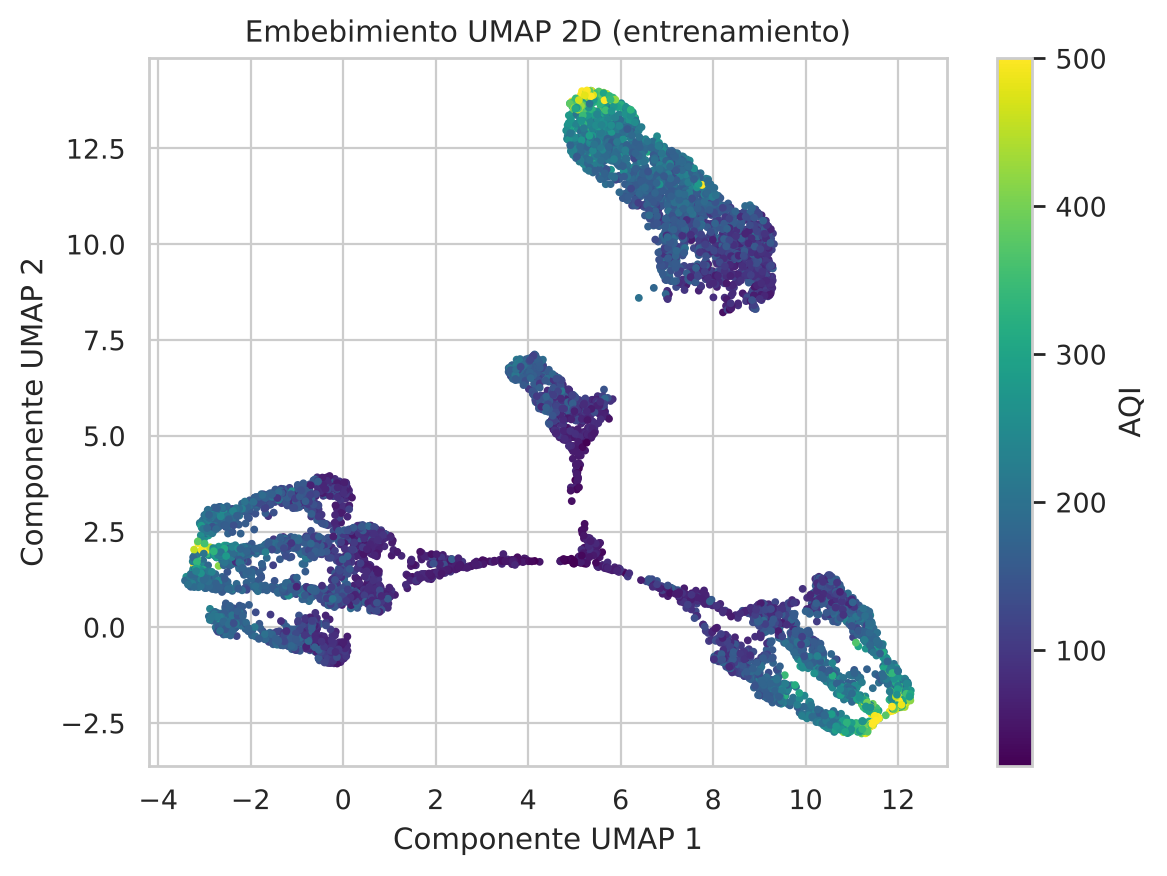

In [25]:
# Visualización del embebimiento UMAP 2D del conjunto de entrenamiento coloreado por AQI
emb = UMAPNoSupervisado(n_components=2).fit(Z).transform(Z)
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(emb[:, 0], emb[:, 1], c=y_train, s=4, cmap="viridis")
plt.colorbar(sc, label="AQI")
ax.set_xlabel("Componente UMAP 1"); ax.set_ylabel("Componente UMAP 2")
ax.set_title("Embebimiento UMAP 2D (entrenamiento)")
plt.tight_layout()
plt.show()

### 4.4 Comparación: espacio original vs. PCA vs. UMAP

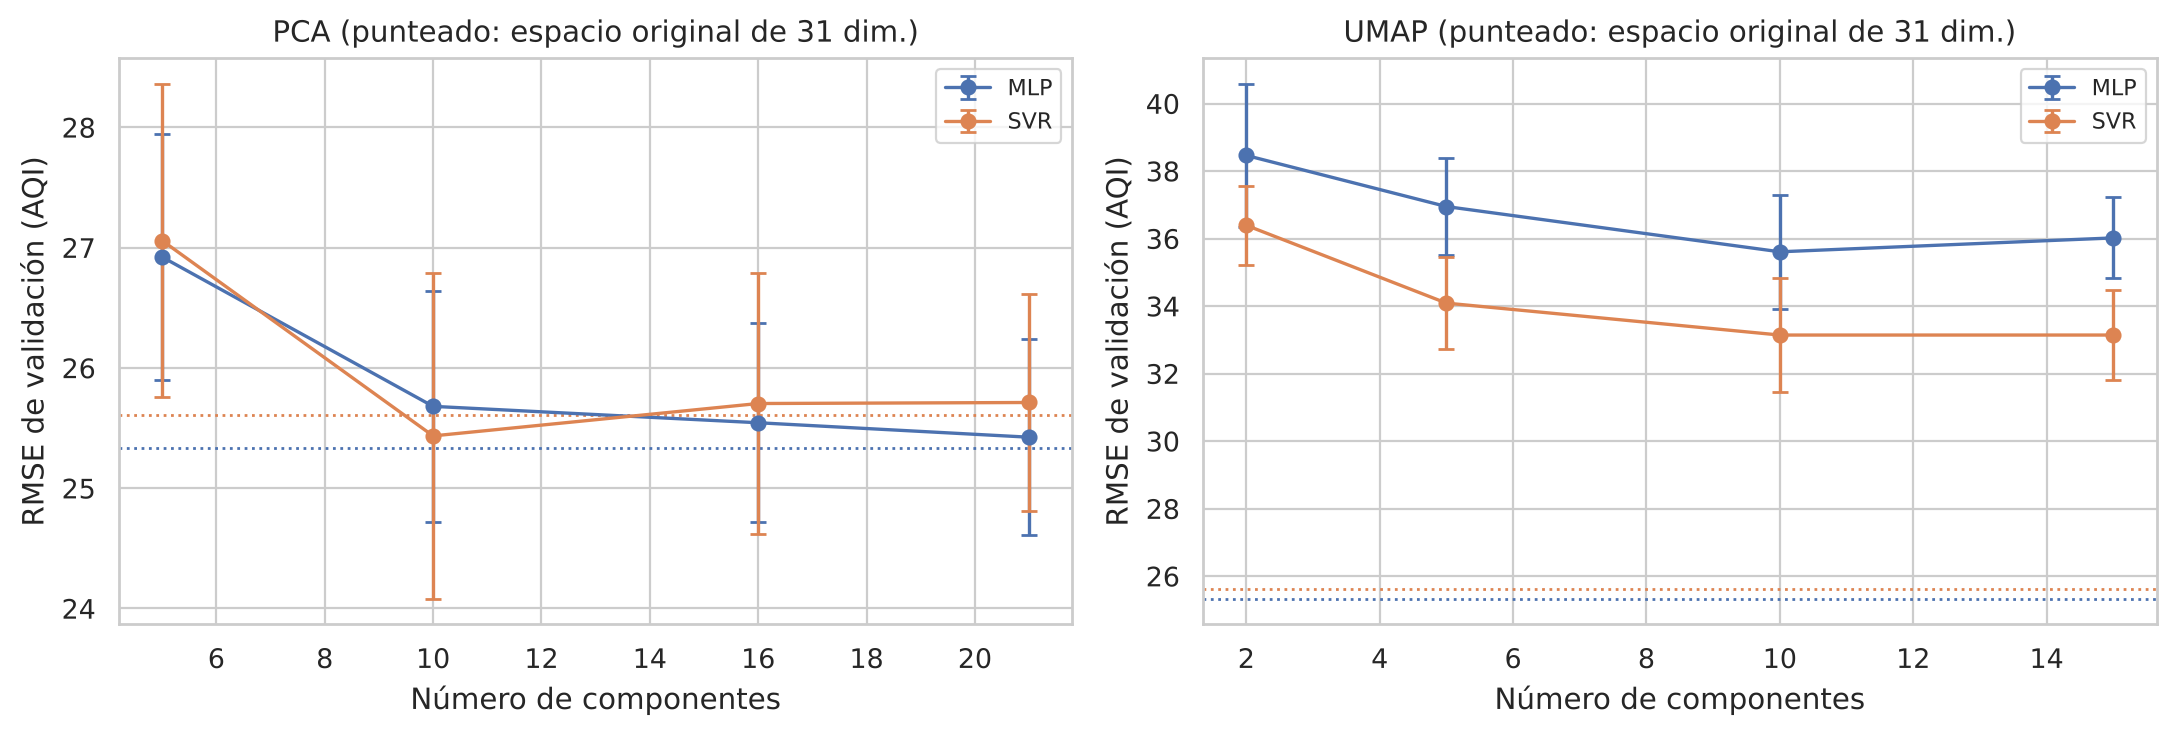

In [26]:
def curva_componentes(curvas, ax, metodo):
    for name, c in curvas.items():
        eb = ax.errorbar(c["k"], c["rmse"], yerr=c["ci"], marker="o", capsize=3, label=name)
        ax.axhline(RESULTS[name]["val_rmse"], ls=":", lw=1, color=eb[0].get_color())
    ax.set_xlabel("Número de componentes"); ax.set_ylabel("RMSE de validación (AQI)")
    ax.set_title(f"{metodo} (punteado: espacio original de {N_FEATURES} dim.)"); ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
curva_componentes(PCA_CURVAS, axes[0], "PCA")
curva_componentes(UMAP_CURVAS, axes[1], "UMAP")
plt.tight_layout()
plt.show()

In [27]:
filas = []
for name in TOP2:
    r = RESULTS[name]
    filas.append({"Modelo": name, "Espacio": "Original", "Dim.": N_FEATURES, "Reducción %": 0.0,
                  "RMSE val": f"{r['val_rmse']:.2f} ± {r['val_rmse_ci']:.2f}",
                  "RMSE test": r["test_rmse"], "MAE test": r["test_mae"], "R² test": r["test_r2"]})
for metodo, lista in [("PCA", PCA_RES), ("UMAP", UMAP_RES)]:
    for r in lista:
        filas.append({"Modelo": r["modelo"].split(" + ")[0], "Espacio": metodo, "Dim.": r["n_comp"],
                      "Reducción %": r["reduccion"],
                      "RMSE val": f"{r['val_rmse']:.2f} ± {r['val_rmse_ci']:.2f}",
                      "RMSE test": r["test_rmse"], "MAE test": r["test_mae"], "R² test": r["test_r2"]})
tabla_red = pd.DataFrame(filas)
tabla_red

,Modelo,Espacio,Dim.,Reducción %,RMSE val,RMSE test,MAE test,R² test
0,MLP,Original,31,0.000,25.33 ± 0.76,25.031,18.154,0.901
1,SVR,Original,31,0.000,25.61 ± 0.75,25.502,18.692,0.897
2,MLP,PCA,21,32.258,25.42 ± 0.82,25.343,18.296,0.899
3,SVR,PCA,10,67.742,25.43 ± 1.35,24.769,17.678,0.903
4,MLP,UMAP,10,67.742,35.61 ± 1.68,36.148,27.197,0.794
5,SVR,UMAP,10,67.742,33.14 ± 1.70,33.347,24.202,0.824


## 5. Conclusiones
Ver las secciones de discusión y conclusiones del informe (`reporte/informe_final.pdf`).